# Cartoonifier, take two (multi-pass OpenCV stylization)

I already did the basic "bilateral filter + edge mask" cartoonify earlier (project 66). This time I wanted to push the OpenCV-only pipeline a bit harder without bringing in a GAN — partly because pulling a 50MB stylization GAN into a portfolio repo feels excessive, and partly because the multi-pass classical pipeline is actually a more interesting comparison than I expected.

What's different here:
- Two passes of bilateral filtering at different scales, then a final `cv2.stylization` call.
- Edge map built from an adaptive threshold on the median-blurred grayscale, instead of just Canny.
- K-means color quantization on the smoothed image so the "cartoon" actually has flat color regions.

I run it on `chelsea`, a real photo of a cat that ships with scikit-image (CC0), so the notebook works on a fresh clone without any image downloads.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data

ART = Path("artifacts"); ART.mkdir(exist_ok=True)

# a real photo that ships with scikit-image: "chelsea" (a cat, CC0)
img_rgb = data.chelsea()
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
print("shape:", img_rgb.shape)

shape: (300, 451, 3)


## Pass 1: multi-scale smoothing

Bilateral filter at a small kernel preserves fine edges but only lightly smooths, then a larger kernel does the heavier flattening. Stacking them is meaningfully different from one call with `d=15`.

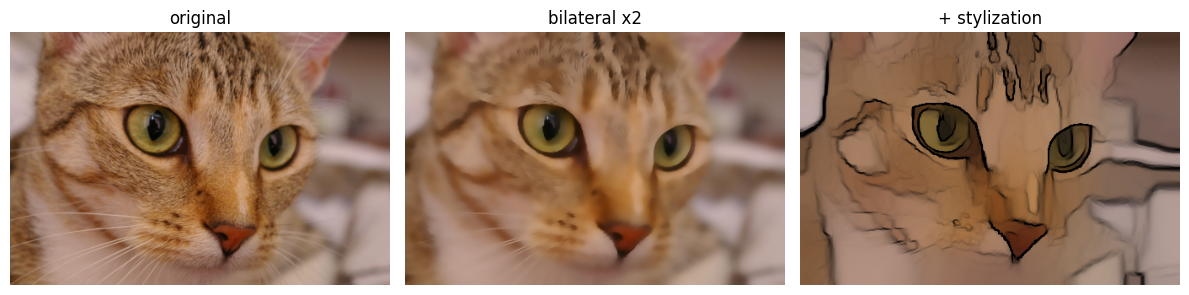

In [2]:
smooth_small = cv2.bilateralFilter(img_bgr, d=5, sigmaColor=40, sigmaSpace=40)
smooth_big   = cv2.bilateralFilter(smooth_small, d=11, sigmaColor=80, sigmaSpace=80)
# one final stylization pass — it's basically a fancier bilateral under the hood
stylized = cv2.stylization(smooth_big, sigma_s=60, sigma_r=0.4)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax,
    [img_rgb, cv2.cvtColor(smooth_big, cv2.COLOR_BGR2RGB), cv2.cvtColor(stylized, cv2.COLOR_BGR2RGB)],
    ["original", "bilateral x2", "+ stylization"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(ART/"smoothing_passes.png", dpi=110); plt.show()

## Pass 2: edge map from adaptive threshold

Canny is fine but it tends to produce thin one-pixel edges that don't read well after you overlay them. Adaptive threshold on a median-blurred gray image gives me thicker, more "drawn-on" lines.

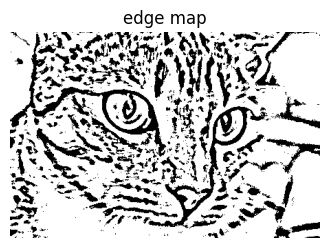

In [3]:
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
gray_blur = cv2.medianBlur(gray, 7)
edges = cv2.adaptiveThreshold(gray_blur, 255,
                              cv2.ADAPTIVE_THRESH_MEAN_C,
                              cv2.THRESH_BINARY, blockSize=9, C=2)

plt.figure(figsize=(4,4))
plt.imshow(edges, cmap="gray"); plt.axis("off"); plt.title("edge map")
plt.savefig(ART/"edges.png", dpi=110); plt.show()

## Pass 3: K-means color quantization

This is the step that actually gives the output its "cartoon" look. Without it, the bilateral output is just a smoother photo.

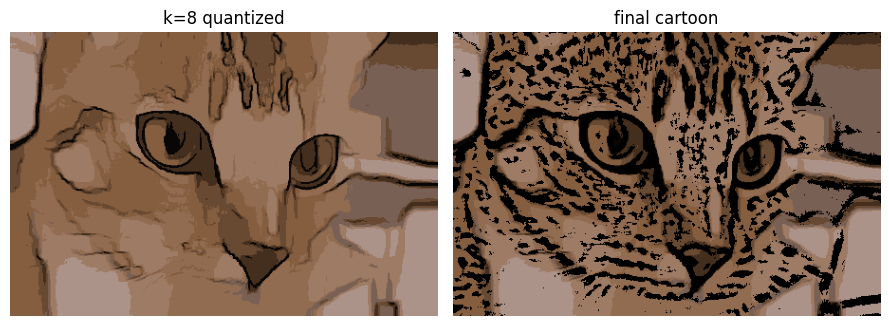

In [4]:
def quantize(img, k=8):
    Z = img.reshape(-1, 3).astype(np.float32)
    # criteria, attempts, flags - same defaults I used last time
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
    _, labels, centers = cv2.kmeans(Z, k, None, criteria, 5, cv2.KMEANS_PP_CENTERS)
    centers = centers.astype(np.uint8)
    return centers[labels.flatten()].reshape(img.shape)

quantized = quantize(stylized, k=8)
cartoon = cv2.bitwise_and(quantized, quantized, mask=edges)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(cv2.cvtColor(quantized, cv2.COLOR_BGR2RGB)); ax[0].set_title("k=8 quantized")
ax[1].imshow(cv2.cvtColor(cartoon, cv2.COLOR_BGR2RGB));   ax[1].set_title("final cartoon")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(ART/"cartoon_final.png", dpi=110); plt.show()

## Notes

On the cat photo, the k=8 quantized image already reads as a cartoon: flat brown and grey regions with clean outlines around the eyes and nose. The final version with the edge map overlaid is busier than I'd like, because the adaptive threshold picks up every stripe in the fur and turns it into a black scribble. A higher `blockSize` or a stronger median blur before thresholding would thin that out; for textured subjects like fur, I'd probably drop the edge overlay entirely.

That's the general trade-off with the classical pipeline. Smooth subjects come out well, but busy textures get a "scribbled all over" look, and that's where a learned model (something like AnimeGAN or White-Box Cartoonization) would earn its keep.

If I were to swap in a learned model, I'd probably grab `animegan2-pytorch` from torch hub since it's small enough to run on CPU. Out of scope for this notebook, but it's the obvious next step.